<a href="https://colab.research.google.com/github/kinjaljoshi/mech-interp-from-scratch/blob/master/1_4_degenerate_eigenvalues.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1.4 · Degenerate eigenvalues: when the eigenvectors are not unique

*Phase 1 — linear algebra for interpretability*

Until now we have quietly assumed that every eigenvalue is different from the others. This notebook asks what happens when two or more eigenvalues are **equal**, or merely close. The short answer is that the eigenvectors stop being well defined, and that has real consequences for PCA, for SVD, and for any attempt to read meaning into a particular direction inside a network.

There are three situations, and we meet them in turn:

- **Exact repeats in a symmetric matrix.** The eigenvectors for the repeated value are not unique: an entire plane (or higher-dimensional subspace) of directions is equally valid.
- **Near repeats.** The eigenvectors are unique on paper but wildly unstable in practice, because noise can swing them by any angle.
- **Exact repeats in a non-symmetric matrix.** There can be *fewer* eigenvectors than eigenvalues, so the matrix cannot be diagonalised at all.

As before, each step is a short note followed by one experiment cell. All numerics are PyTorch; matplotlib only draws.

1. Repeated eigenvalues: the simplest case
2. An eigenspace, and the freedom inside it
3. The computer's choice is arbitrary, the subspace is not
4. Near-degeneracy: when the gap is smaller than the noise
5. What this does to PCA
6. The non-symmetric twist: defective matrices
7. A preview from Phase 4: the pentagon

## Setup

Same conventions as before. Black is used for the repeated-eigenvalue cases we want to contrast with the ordinary ones. The helpers `eig_sym` (from 1.2) and `deflection` (from 1.1) are reused, and `line_angle_deg` measures the angle between two directions treated as lines, so that $v$ and $-v$ count as the same direction.

In [2]:
import math
import torch
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers the 3D projection)

torch.manual_seed(0)
torch.set_default_dtype(torch.float64)
torch.set_printoptions(precision=4, sci_mode=False, linewidth=120)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})

C_IN, C_OUT = "#6b7280", "#2563eb"          # reference (grey), main subject (blue)
C_V1, C_V2 = "#d97706", "#9333ea"           # first and second eigen-direction (orange, purple)

theta = torch.linspace(0, 2 * math.pi, 400)
circle = torch.stack([theta.cos(), theta.sin()])


def eig_sym(S):
    """Eigen-decomposition of a symmetric matrix, largest eigenvalue first. Columns of Q are orthonormal eigenvectors."""
    lam, Q = torch.linalg.eigh(S)                        # ascending order
    order = lam.argsort(descending=True)
    return lam[order], Q[:, order]


def line_angle_deg(u, v):
    """Angle in degrees between two directions, treated as lines (so v and −v are the same)."""
    u, v = u / u.norm(), v / v.norm()
    if (u @ v) < 0:
        v = -v                                           # compare the lines, not the arrows
    # 2·atan2(‖u − v‖, ‖u + v‖) stays accurate for tiny angles, where acos(u·v) would round to exactly zero
    return math.degrees(2 * torch.atan2((u - v).norm(), (u + v).norm()).item())


def deflection(M, theta):
    """Angle (radians) by which M turns the direction at angle theta, folded so a flip counts as 'no turn'."""
    u = torch.stack([theta.cos(), theta.sin()])
    Mu = M @ u
    cross = u[0] * Mu[1] - u[1] * Mu[0]
    dot = (u * Mu).sum(0)
    d = torch.atan2(cross, dot)
    return d - math.pi * torch.round(d / math.pi)


def grid_segments(lim=2, n=41):
    """Lattice lines x = k and y = k for integer k in [-lim, lim], each as a (2, n) tensor of points."""
    t = torch.linspace(-lim, lim, n)
    ones = torch.ones(n)
    segs = []
    for k in range(-lim, lim + 1):
        segs.append(torch.stack([k * ones, t]))
        segs.append(torch.stack([t, k * ones]))
    return segs


def draw_space(ax, M, title, lim=4.5):
    """Lattice and unit circle after applying M (pass the identity for 'before')."""
    for i, s in enumerate(grid_segments()):
        p = M @ s
        ax.plot(p[0], p[1], color=C_IN, lw=0.7, alpha=0.45, label="lattice" if i == 0 else None)
    c = M @ circle
    ax.plot(c[0], c[1], color=C_OUT, lw=2, label="unit circle")
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_aspect("equal"); ax.grid(False)
    ax.axhline(0, color="k", lw=0.4, zorder=0); ax.axvline(0, color="k", lw=0.4, zorder=0)
    ax.set_title(title)


print("torch", torch.__version__)

torch 2.11.0+cpu


## Step 1 · Repeated eigenvalues: the simplest case

Two numbers describe how often an eigenvalue $\lambda$ occurs:

- its **algebraic multiplicity**: how many times $\lambda$ is a root of the characteristic polynomial $\det(M - \lambda I)$;
- its **geometric multiplicity**: the dimension of its eigenspace $E_\lambda = \ker(M - \lambda I)$, which is $d - \operatorname{rank}(M - \lambda I)$.

The geometric multiplicity is never larger than the algebraic one. For symmetric matrices the two are always equal, which is the spectral theorem again: a repeated eigenvalue comes with a full set of eigenvectors, not fewer.

The most extreme case is $M = 3I$. Its characteristic polynomial is $(\lambda - 3)^2$, so $\lambda = 3$ is a double root, and $M - 3I$ is the zero matrix, which has rank 0. Both equations in $(M - 3I)v = 0$ are empty, so *every* vector solves it. In notebook 1.1 we searched for directions a matrix does not turn; for $3I$ the answer is all of them.

In [3]:
M = 3 * torch.eye(2)
print("eigenvalues of 3I:", torch.linalg.eigvalsh(M))
print("M − 3I =\n", M - 3 * torch.eye(2))

rank = torch.linalg.matrix_rank(M - 3 * torch.eye(2)).item()
print(f"\nrank(M − 3I) = {rank}   →   eigenspace dimension = 2 − {rank} = {2 - rank}")
assert rank == 0

v = torch.randn(2, 1000)
assert torch.allclose(M @ v, 3 * v)
print("M v = 3 v holds for 1000 random vectors v: every direction is an eigen-direction")

eigenvalues of 3I: tensor([3., 3.])
M − 3I =
 tensor([[0., 0.],
        [0., 0.]])

rank(M − 3I) = 0   →   eigenspace dimension = 2 − 0 = 2
M v = 3 v holds for 1000 random vectors v: every direction is an eigen-direction


Here it is as a picture. The left panel shows six random directions and their images under $3I$: every arrow stays on its own line. The right panel repeats the "how far does the matrix turn each direction?" curve from 1.1. For an ordinary symmetric matrix, here $S = \begin{pmatrix}5&2\\2&2\end{pmatrix}$, it crosses zero at exactly two directions. For $3I$ it is flat at zero everywhere.

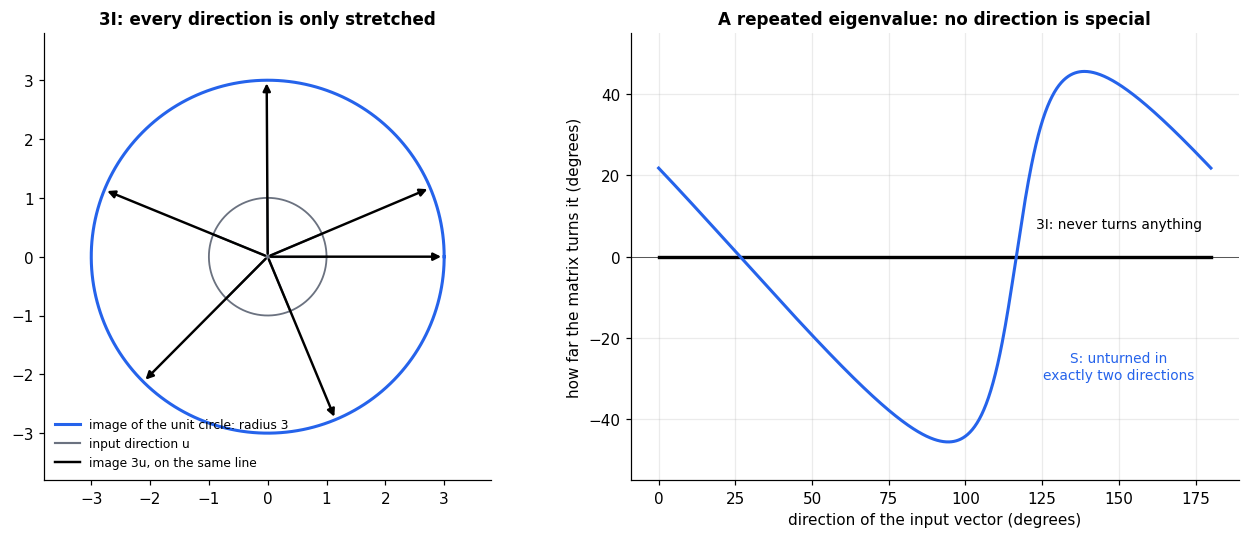

In [4]:
S = torch.tensor([[5.0, 2.0], [2.0, 2.0]])
thetas = torch.linspace(0, math.pi, 721)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
ax.plot(circle[0], circle[1], color=C_IN, lw=1.2)
img = M @ circle
ax.plot(img[0], img[1], color=C_OUT, lw=2, label="image of the unit circle: radius 3")
for a in torch.linspace(0.4, 2 * math.pi, 6):
    u = torch.stack([a.cos(), a.sin()])
    ax.plot([0, u[0]], [0, u[1]], color=C_IN, lw=1.4)
    ax.annotate("", xy=(M @ u).tolist(), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color="black", lw=1.6), zorder=5)
ax.plot([], [], color=C_IN, lw=1.4, label="input direction u")
ax.plot([], [], color="black", lw=1.6, label="image 3u, on the same line")
ax.set_xlim(-3.8, 3.8); ax.set_ylim(-3.8, 3.8); ax.set_aspect("equal"); ax.grid(False)
ax.legend(loc="lower left", fontsize=8, frameon=False)
ax.set_title("3I: every direction is only stretched")

ax = axes[1]
ax.plot(torch.rad2deg(thetas), torch.rad2deg(deflection(M, thetas)), color="black", lw=2.2)
ax.plot(torch.rad2deg(thetas), torch.rad2deg(deflection(S, thetas)), color=C_OUT, lw=2)
ax.text(150, 7, "3I: never turns anything", fontsize=9, ha="center")
ax.text(150, -30, "S: unturned in\nexactly two directions", fontsize=9, color=C_OUT, ha="center")
ax.axhline(0, color="k", lw=0.5, zorder=0)
ax.set_ylim(-55, 55)
ax.set_xlabel("direction of the input vector (degrees)"); ax.set_ylabel("how far the matrix turns it (degrees)")
ax.set_title("A repeated eigenvalue: no direction is special")
plt.tight_layout(); plt.show()

## Step 2 · An eigenspace, and the freedom inside it

Most matrices with a repeated eigenvalue are not as plain as $3I$. Let's use a 3×3 symmetric matrix with eigenvalues $(5, 2, 2)$: one unique axis, plus a repeated eigenvalue 2. To get a matrix that does not look diagonal, we build it as $M = Q_0\,\mathrm{diag}(5,2,2)\,Q_0^\top$ with $Q_0$ a random orthonormal basis, so the true structure is hidden in a rotated frame.

The eigenvectors for $\lambda = 5$ are unique up to sign. The eigenvectors for $\lambda = 2$ are a different story. Any vector in the plane $E_2 = \operatorname{span}(q_2, q_3)$ satisfies $Mv = 2v$, so we are free to choose *any* orthonormal pair inside that plane. The spectral theorem promises that an orthonormal eigenbasis exists, but not that it is unique. Exactly what freedom is left? For an eigenvalue with multiplicity $k$, any $k \times k$ orthogonal matrix applied inside its eigenspace gives another valid basis. Here that means a rotation by any angle, possibly combined with a reflection.

Let's check what `eigh` returns against the basis we built the matrix from.

In [5]:
torch.manual_seed(5)
Q0, _ = torch.linalg.qr(torch.randn(3, 3))                 # a random orthonormal basis of 3-space
lam_true = torch.tensor([5.0, 2.0, 2.0])                   # the eigenvalue 2 is repeated
M3 = Q0 @ torch.diag(lam_true) @ Q0.T
M3 = (M3 + M3.T) / 2                                       # remove tiny rounding asymmetry

lam3, V3 = eig_sym(M3)
print("eigenvalues found by eigh:", lam3)

plane = Q0[:, 1:]                                          # the plane we built in: the λ = 2 eigenspace
P_plane = plane @ plane.T                                  # projector onto that plane

c5 = (V3[:, 0] @ Q0[:, 0]).abs().item()
leak = ((torch.eye(3) - P_plane) @ V3[:, 1:]).abs().max().item()
print(f"\nλ = 5: |cos| between eigh's vector and ours = {c5:.12f}   (the same axis, up to sign)")
print(f"λ = 2: eigh's two vectors lie in our plane (largest component outside it: {leak:.1e})")
print(f"       but eigh's first vector is {line_angle_deg(V3[:, 1], Q0[:, 1]):.1f}° from our second basis vector "
      f"and {line_angle_deg(V3[:, 1], Q0[:, 2]):.1f}° from our third")
assert abs(c5 - 1) < 1e-10 and leak < 1e-10

# any rotation inside the eigenplane gives another equally valid set of eigenvectors
phi = math.radians(40)
R = torch.tensor([[math.cos(phi), -math.sin(phi)], [math.sin(phi), math.cos(phi)]])
V3_alt = V3.clone()
V3_alt[:, 1:] = V3[:, 1:] @ R

print("\nafter rotating the pair by 40° inside the plane:")
print("  largest residual of M v = λ v :", (M3 @ V3_alt - V3_alt * lam3).abs().max().item())
print("  still orthonormal             :", torch.allclose(V3_alt.T @ V3_alt, torch.eye(3)))
print("  still reconstructs M = VΛVᵀ   :", torch.allclose(V3_alt @ torch.diag(lam3) @ V3_alt.T, M3))
assert torch.allclose(M3 @ V3_alt, V3_alt * lam3) and torch.allclose(V3_alt @ torch.diag(lam3) @ V3_alt.T, M3)

eigenvalues found by eigh: tensor([5.0000, 2.0000, 2.0000])

λ = 5: |cos| between eigh's vector and ours = 1.000000000000   (the same axis, up to sign)
λ = 2: eigh's two vectors lie in our plane (largest component outside it: 1.7e-16)
       but eigh's first vector is 38.0° from our second basis vector and 52.0° from our third

after rotating the pair by 40° inside the plane:
  largest residual of M v = λ v : 8.881784197001252e-16
  still orthonormal             : True
  still reconstructs M = VΛVᵀ   : True


In picture form: the orange line is the unique axis. The grey disc is the eigenplane for $\lambda = 2$. The purple pair is the basis `eigh` returned, the black pair is the same basis rotated by 40° inside the plane, and both are perfectly good sets of eigenvectors. So is every other orthonormal pair on the ring.

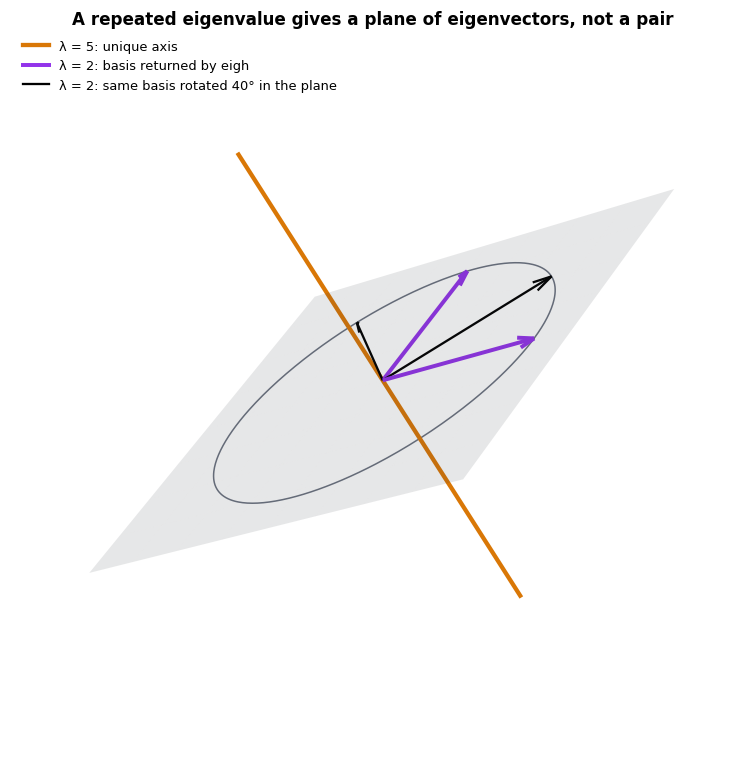

In [6]:
fig = plt.figure(figsize=(8.5, 7))
ax = fig.add_subplot(projection="3d")

g = torch.linspace(-1.25, 1.25, 9)
a, b = torch.meshgrid(g, g, indexing="ij")
Pt = a[..., None] * V3[:, 1] + b[..., None] * V3[:, 2]            # points of the λ = 2 plane
ax.plot_surface(Pt[..., 0].numpy(), Pt[..., 1].numpy(), Pt[..., 2].numpy(), color=C_IN, alpha=0.12, linewidth=0)
ring = torch.cos(theta)[:, None] * V3[:, 1] + torch.sin(theta)[:, None] * V3[:, 2]
ax.plot(ring[:, 0].numpy(), ring[:, 1].numpy(), ring[:, 2].numpy(), color=C_IN, lw=1.0)

v1 = V3[:, 0]
ax.plot([-1.4 * v1[0].item(), 1.4 * v1[0].item()], [-1.4 * v1[1].item(), 1.4 * v1[1].item()],
        [-1.4 * v1[2].item(), 1.4 * v1[2].item()], color=C_V1, lw=2.8)
for i in (1, 2):
    ax.quiver(0, 0, 0, *V3[:, i].tolist(), color=C_V2, linewidth=2.6, arrow_length_ratio=0.1)
    ax.quiver(0, 0, 0, *V3_alt[:, i].tolist(), color="black", linewidth=1.5, arrow_length_ratio=0.1)

ax.plot([], [], [], color=C_V1, lw=2.8, label="λ = 5: unique axis")
ax.plot([], [], [], color=C_V2, lw=2.6, label="λ = 2: basis returned by eigh")
ax.plot([], [], [], color="black", lw=1.5, label="λ = 2: same basis rotated 40° in the plane")
ax.legend(loc="upper left", fontsize=8.5, frameon=False)
ax.set_xlim(-1.25, 1.25); ax.set_ylim(-1.25, 1.25); ax.set_zlim(-1.25, 1.25)
ax.set_box_aspect((1, 1, 1), zoom=1.15); ax.set_axis_off(); ax.view_init(elev=22, azim=35)
ax.set_title("A repeated eigenvalue gives a plane of eigenvectors, not a pair", pad=0)
fig.subplots_adjust(left=0, right=1, bottom=0, top=0.94)
plt.show()

## Step 3 · The computer's choice is arbitrary, the subspace is not

If any basis in the eigenplane is valid, which one does `eigh` return? Whichever its algorithm lands on, and that depends on the exact floating-point values in the matrix. We can see how arbitrary it is by nudging $M$ with a symmetric perturbation of size $10^{-10}$, far below anything that matters in practice, and recomputing.

Perturbation theory predicts three things. Eigenvalues move by at most about the size of the perturbation. The *unique* eigenvector moves by about (size of perturbation) / (gap to the other eigenvalues), so barely at all. But the perturbation breaks the tie between the two equal eigenvalues, and the eigenvectors inside the plane snap to whichever in-plane directions the perturbation prefers, however small it is. Those can be anywhere.

What stays put is the **projector** $P = V_2 V_2^\top$ onto the eigenplane, because it does not depend on which basis we use inside it. The lesson, which we'll lean on for the rest of the project: *ask questions about subspaces, not about individual vectors in a degenerate subspace.*

In [7]:
torch.manual_seed(11)
P0 = V3[:, 1:] @ V3[:, 1:].T                                # projector onto the λ = 2 plane

print(f"{'trial':>5} {'λ moved by':>12} {'unique axis moved':>19} {'v₂ rotated by':>15} {'projector moved':>17}")
worst = dict(dl=0.0, a0=0.0, a1=0.0, dP=0.0)
for t in range(6):
    E = torch.randn(3, 3)
    E = (E + E.T) / 2 * 1e-10                              # a tiny symmetric perturbation
    lamE, VE = eig_sym(M3 + E)
    PE = VE[:, 1:] @ VE[:, 1:].T
    dl = (lamE - lam3).abs().max().item()
    a0 = line_angle_deg(V3[:, 0], VE[:, 0])
    a1 = line_angle_deg(V3[:, 1], VE[:, 1])
    dP = (PE - P0).norm().item()
    print(f"{t:>5} {dl:>12.1e} {a0:>18.1e}° {a1:>14.1f}° {dP:>17.1e}")
    worst = dict(dl=max(worst["dl"], dl), a0=max(worst["a0"], a0), a1=max(worst["a1"], a1), dP=max(worst["dP"], dP))

assert worst["dl"] < 1e-9 and worst["a0"] < 1e-6 and worst["dP"] < 1e-9
assert worst["a1"] > 5
print("\nA 1e-10 nudge leaves the eigenvalues, the unique axis and the eigenplane essentially untouched,")
print(f"but it rotated the individual in-plane eigenvectors by up to {worst['a1']:.0f}°.")

trial   λ moved by   unique axis moved   v₂ rotated by   projector moved
    0      8.9e-11            9.5e-10°           87.4°           2.3e-11
    1      1.0e-10            1.5e-09°           43.9°           3.8e-11
    2      1.7e-10            4.1e-09°           82.7°           1.0e-10
    3      1.5e-10            2.5e-09°            3.5°           6.1e-11
    4      1.1e-10            1.9e-09°           57.3°           4.7e-11
    5      1.1e-10            2.1e-09°           51.4°           5.3e-11

A 1e-10 nudge leaves the eigenvalues, the unique axis and the eigenplane essentially untouched,
but it rotated the individual in-plane eigenvectors by up to 87°.


## Step 4 · Near-degeneracy: when the gap is smaller than the noise

Exact ties are rare in real data, but near-ties are everywhere, and they cause the same problem in a milder form. The standard result (Davis–Kahan) says that if a symmetric matrix is perturbed by $E$, its eigenvector rotates by an angle of roughly

$$\theta \;\lesssim\; \frac{\lVert E\rVert}{\text{gap}}$$

where the gap is the distance from its eigenvalue to the nearest other one. A large gap makes the eigenvector robust. A gap smaller than the noise makes it meaningless.

We can test this in 2×2, where everything is explicit. Take $M(\varepsilon) = \operatorname{diag}(1+\varepsilon,\, 1)$, whose top eigenvector is exactly the $x$-axis, and add a random symmetric perturbation with entries of size $\delta = 0.01$. The top eigenvector of the perturbed matrix sits at the exact angle $\tfrac12\operatorname{atan2}(2E_{12},\ \varepsilon + E_{11} - E_{22})$, which we verify against `eigh`. We then sweep the gap $\varepsilon$ over four orders of magnitude, with 400 random perturbations at each value.

✓ eigh agrees with the closed-form angle ½·atan2(2E₁₂, ε + E₁₁ − E₂₂)
gap ε = 1e-04:  median error  43.877°   (80% of trials between 13.467° and 77.22°)
gap ε = 1e-02:  median error  28.416°   (80% of trials between 6.070° and 62.04°)
gap ε = 1e+00:  median error   0.385°   (80% of trials between 0.082° and 0.92°)


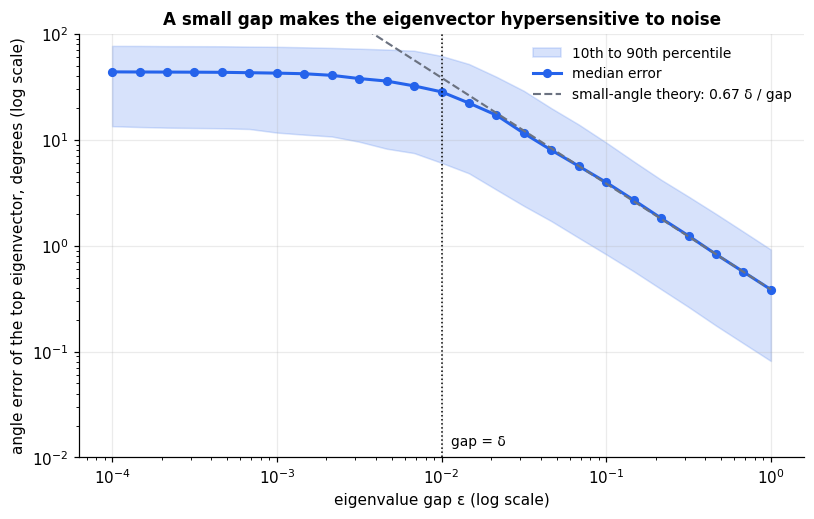

In [8]:
torch.manual_seed(7)
delta = 0.01                                               # size of the perturbation (think: sampling noise)
trials = 400
eps_grid = torch.logspace(-4, 0, 25)                       # the eigenvalue gap, from 1e-4 to 1
E11, E22, E12 = torch.randn(3, trials) * delta             # one random symmetric perturbation per trial

eps = eps_grid[:, None]                                    # (25, 1), broadcasts against (trials,)
Mb = torch.zeros(len(eps_grid), trials, 2, 2)
Mb[..., 0, 0] = 1 + eps + E11
Mb[..., 1, 1] = 1 + E22
Mb[..., 0, 1] = E12
Mb[..., 1, 0] = E12

lamb, Vb = torch.linalg.eigh(Mb)                           # ascending, so the top eigenvector is the last column
top = Vb[..., :, -1]                                       # (25, trials, 2)
ang = torch.rad2deg(torch.acos(top[..., 0].abs().clamp(max=1.0)))        # angle away from the unperturbed x-axis

closed = torch.rad2deg(0.5 * torch.atan2(2 * E12, eps + E11 - E22)).abs()
assert torch.allclose(ang, closed, atol=1e-6)
print("✓ eigh agrees with the closed-form angle ½·atan2(2E₁₂, ε + E₁₁ − E₂₂)")

q = torch.quantile(ang, torch.tensor([0.1, 0.5, 0.9]), dim=1)            # (3, 25)
for k in (0, 12, 24):
    print(f"gap ε = {eps_grid[k]:.0e}:  median error {q[1, k]:7.3f}°   (80% of trials between {q[0, k]:.3f}° and {q[2, k]:.2f}°)")

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.fill_between(eps_grid.numpy(), q[0].numpy(), q[2].numpy(), color=C_OUT, alpha=0.18, label="10th to 90th percentile")
ax.plot(eps_grid.numpy(), q[1].numpy(), "o-", color=C_OUT, lw=2, ms=5, label="median error")
small = torch.rad2deg(torch.tensor(0.6745 * delta) / eps_grid)
ax.plot(eps_grid.numpy(), small.numpy(), "--", color=C_IN, lw=1.4, label="small-angle theory: 0.67 δ / gap")
ax.axvline(delta, color="black", lw=1, ls=":")
ax.text(delta * 1.15, 0.013, "gap = δ", fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(0.01, 100)
ax.set_xlabel("eigenvalue gap ε (log scale)"); ax.set_ylabel("angle error of the top eigenvector, degrees (log scale)")
ax.legend(frameon=False, fontsize=9, loc="upper right")
ax.set_title("A small gap makes the eigenvector hypersensitive to noise")
plt.show()

## Step 5 · What this does to PCA

In PCA the "noise" is sampling error. A covariance matrix estimated from $N$ samples has entries off by roughly $\sqrt{\lambda_i\lambda_j/N}$, so the principal axes $i$ and $j$ can be told apart only when their eigenvalue gap is comfortably larger than that.

To see it, we'll generate many datasets with a known covariance, $\operatorname{diag}(\lambda_1, \lambda_2)$, so the true first principal axis is the $x$-axis (0°). We run PCA on 400 independent datasets of 300 samples each and look at the angle PC1 comes out at. Three cases: a large gap, a small gap, and no gap at all, where the true covariance is the identity and no first axis exists. All three use the same underlying random numbers, so the only thing that differs is the covariance.

gap 5.0  λ = (6.0, 1.0)   within ±10° of the true axis: 100.0%    median |error|:   1.0°
gap 0.2  λ = (1.2, 1.0)   within ±10° of the true axis: 42.5%    median |error|:  12.0°
no gap   λ = (1.0, 1.0)   within ±10° of the true axis: 11.2%    median |error|:  46.3°


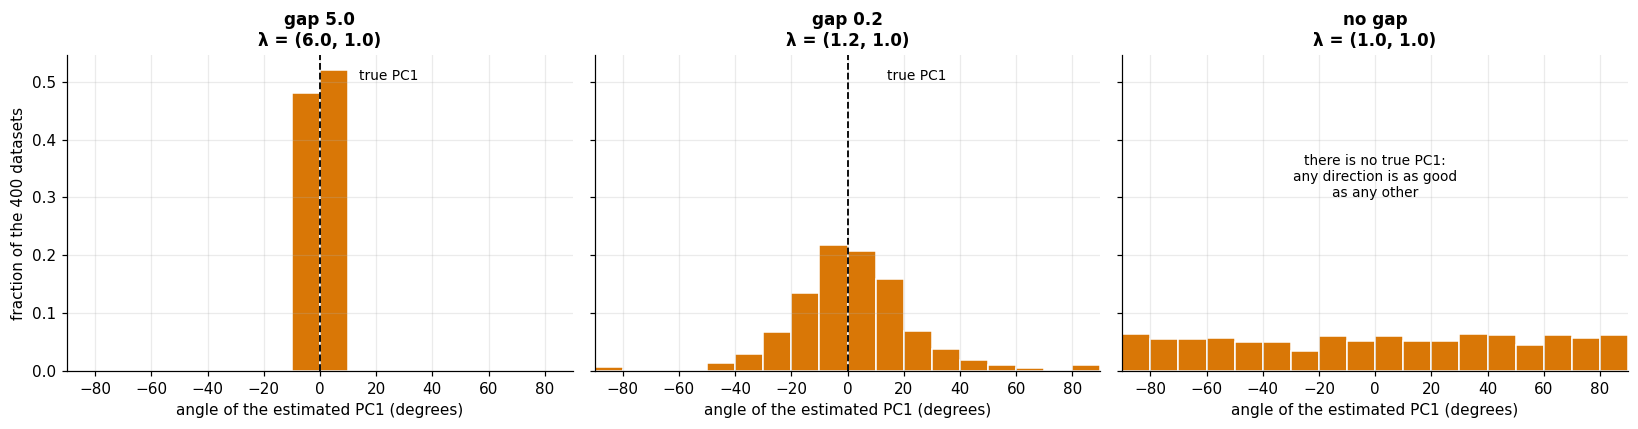

In [9]:
def pc1_angles(lam_pair, N=300, reps=400, seed=0):
    """Angle (degrees, in [−90, 90)) of the estimated PC1 for many independent datasets with covariance diag(lam_pair)."""
    g = torch.Generator().manual_seed(seed)
    Z = torch.randn(reps, N, 2, generator=g)
    X = Z * torch.tensor(lam_pair).sqrt()                  # covariance diag(lam_pair): the true PC1 is the x-axis
    Xc = X - X.mean(1, keepdim=True)
    C = Xc.transpose(1, 2) @ Xc / (N - 1)                  # one 2×2 covariance matrix per dataset
    _, V = torch.linalg.eigh(C)
    v = V[:, :, -1]                                        # top eigenvector of each
    a = torch.rad2deg(torch.atan2(v[:, 1], v[:, 0]))
    return (a + 90) % 180 - 90                             # fold: an axis is a line


cases = [("gap 5.0\nλ = (6.0, 1.0)", (6.0, 1.0)), ("gap 0.2\nλ = (1.2, 1.0)", (1.2, 1.0)), ("no gap\nλ = (1.0, 1.0)", (1.0, 1.0))]
results = []
for name, lp in cases:
    a = pc1_angles(lp)
    results.append(a)
    print(f"{name.splitlines()[0]:<8} {name.splitlines()[1]:<16} within ±10° of the true axis: {(a.abs() < 10).double().mean():5.1%}"
          f"    median |error|: {a.abs().median():5.1f}°")

assert (results[0].abs() < 10).double().mean() > 0.99
assert 0.05 < (results[2].abs() < 10).double().mean() < 0.20     # a uniformly random angle lands within ±10° about 11% of the time

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
bins = torch.linspace(-90, 90, 19).numpy()
for i, (ax, (name, _)) in enumerate(zip(axes, cases)):
    a = results[i]
    ax.hist(a.numpy(), bins=bins, weights=(torch.ones_like(a) / len(a)).numpy(), color=C_V1, edgecolor="white")
    if i < 2:
        ax.axvline(0, color="black", ls="--", lw=1.2)
        ax.text(14, ax.get_ylim()[1] * 0.92, "true PC1", fontsize=9)
    else:
        ax.text(0, 0.30, "there is no true PC1:\nany direction is as good\nas any other", ha="center", fontsize=9)
    ax.set_xlim(-90, 90); ax.set_title(name)
    ax.set_xlabel("angle of the estimated PC1 (degrees)")
axes[0].set_ylabel("fraction of the 400 datasets")
plt.tight_layout(); plt.show()

## Step 6 · The non-symmetric twist: defective matrices

So far every repeated eigenvalue has been generous: a repeated eigenvalue came with a full eigenspace. For non-symmetric matrices this can fail. The **shear**

$$J = \begin{pmatrix} 1 & 1 \\ 0 & 1 \end{pmatrix}$$

has characteristic polynomial $(\lambda - 1)^2$, so $\lambda = 1$ has algebraic multiplicity 2. But $J - I = \begin{pmatrix} 0 & 1 \\ 0 & 0 \end{pmatrix}$ has rank 1, so the eigenspace is only a line: the geometric multiplicity is 1. There is one eigen-direction (the $x$-axis) where there should be two, and $J$ cannot be written as $V\Lambda V^{-1}$ because there is no invertible $V$ to be had. Such a matrix is called **defective**.

Numerically the solver still returns two eigenvectors, but they are parallel. Their matrix $V$ is singular, which shows up as an absurdly large condition number.

eigenvalues: tensor([1., 1.])
eigenvector matrix V returned by eig:
 tensor([[ 1.0000, -1.0000],
        [ 0.0000,  0.0000]])
condition number of V: 9.0e+15   (the two columns are parallel, so V cannot really be inverted)

rank(J − I) = 1   →   geometric multiplicity 1, algebraic multiplicity 2

J¹⁰ =
 tensor([[ 1., 10.],
        [ 0.,  1.]]) 
(the off-diagonal entry grows like k, not exponentially: a defective matrix is not a pure scaling)


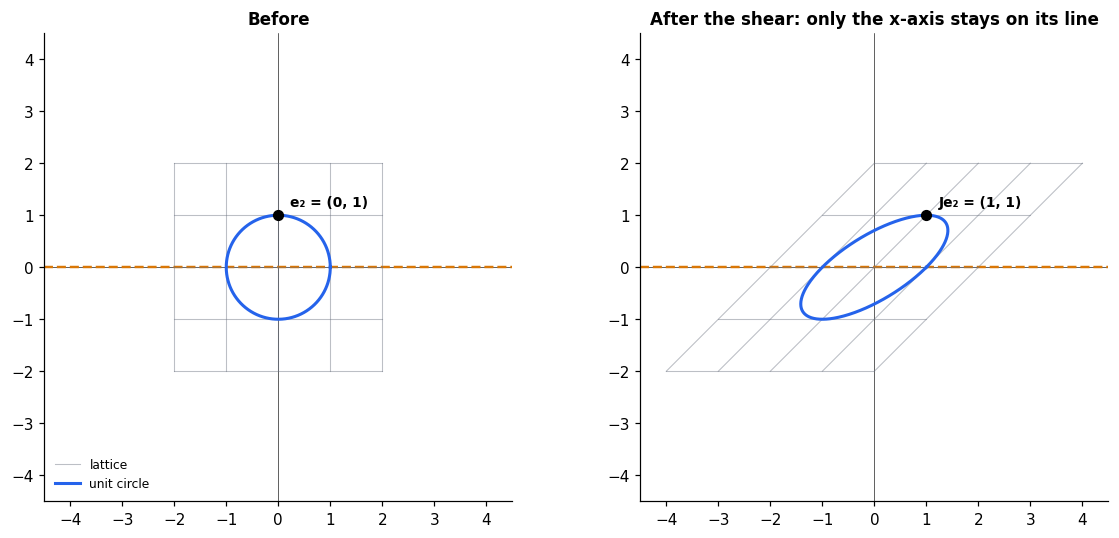

In [10]:
J = torch.tensor([[1.0, 1.0], [0.0, 1.0]])
w, Vj = torch.linalg.eig(J)
print("eigenvalues:", w.real)
print("eigenvector matrix V returned by eig:\n", Vj.real)
cond = torch.linalg.cond(Vj.real).item()
print(f"condition number of V: {cond:.1e}   (the two columns are parallel, so V cannot really be inverted)")

r = torch.linalg.matrix_rank(J - torch.eye(2)).item()
print(f"\nrank(J − I) = {r}   →   geometric multiplicity {2 - r}, algebraic multiplicity 2")
assert r == 1 and cond > 1e10

print("\nJ¹⁰ =\n", torch.linalg.matrix_power(J, 10), "\n(the off-diagonal entry grows like k, not exponentially: a defective matrix is not a pure scaling)")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
draw_space(axes[0], torch.eye(2), "Before")
draw_space(axes[1], J, "After the shear: only the x-axis stays on its line")
for ax in axes:
    ax.plot([-5, 5], [0, 0], color=C_V1, ls="--", lw=1.6, zorder=1)
axes[0].scatter([0], [1], color="black", s=40, zorder=6); axes[0].annotate("e₂ = (0, 1)", (0, 1), (8, 6), textcoords="offset points", fontsize=9, weight="bold")
axes[1].scatter([1], [1], color="black", s=40, zorder=6); axes[1].annotate("Je₂ = (1, 1)", (1, 1), (8, 6), textcoords="offset points", fontsize=9, weight="bold")
axes[0].legend(loc="lower left", fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

Defectiveness also makes eigenvalues fragile. Nudge the shear's bottom-left entry from $0$ to $\varepsilon$ and its eigenvalues become $1 \pm \sqrt{\varepsilon}$, which move by far more than $\varepsilon$ itself. A symmetric matrix with the same repeated eigenvalue, nudged by the same amount, moves its eigenvalues by only $\varepsilon$.

In [11]:
print(f"{'ε':>8} {'nudged shear: λ moves by':>26} {'nudged symmetric: λ moves by':>31}")
for eps_ in (1e-4, 1e-8, 1e-12):
    Jd = torch.tensor([[1.0, 1.0], [eps_, 1.0]])           # defective matrix, nudged
    Sd = torch.tensor([[1.0, eps_], [eps_, 1.0]])          # symmetric matrix with the same eigenvalue 1, nudged equally
    dev_j = (torch.linalg.eigvals(Jd).real - 1).abs().max().item()
    dev_s = (torch.linalg.eigvalsh(Sd) - 1).abs().max().item()
    print(f"{eps_:>8.0e} {dev_j:>26.1e} {dev_s:>31.1e}")
    assert abs(dev_j / math.sqrt(eps_) - 1) < 0.1 and abs(dev_s / eps_ - 1) < 1e-3
print("\nthe shear moves like √ε, the symmetric matrix like ε")

       ε   nudged shear: λ moves by    nudged symmetric: λ moves by
   1e-04                    1.0e-02                         1.0e-04
   1e-08                    1.0e-04                         1.0e-08
   1e-12                    1.0e-06                         1.0e-12

the shear moves like √ε, the symmetric matrix like ε


## Step 7 · A preview from Phase 4: the pentagon

Why does any of this matter for interpretability? In the toy models of superposition, a network squeezes 5 features into 2 dimensions, and (when the features are sparse enough) the solution that emerges is a **regular pentagon**: five unit vectors at $72°$ spacing. Let $W$ be the $2 \times 5$ matrix whose columns are these feature vectors.

Two Gram matrices describe $W$, and both are degenerate.

- In the hidden space, $WW^\top = \sum_k w_k w_k^\top$ equals $\tfrac{5}{2} I_2$ exactly. For evenly spaced unit vectors the second-moment matrix is a multiple of the identity.
- In feature space, $W^\top W$ is $5\times5$ with eigenvalues $(\tfrac52, \tfrac52, 0, 0, 0)$: a repeated eigenvalue again.

So the eigenvectors and singular vectors of a perfectly symmetric solution are not unique: rotate the whole pentagon by any angle and every second-order statistic is unchanged. The quadratic form $u^\top W W^\top u$ (the variance along direction $u$, from 1.2 and 1.3) is flat. Neither PCA nor SVD can single out an orientation, and that is the situation in which a method that selects directions by *sparsity* instead of variance, such as a sparse autoencoder, has something to offer.

W Wᵀ =
 tensor([[2.5000, 0.0000],
        [0.0000, 2.5000]]) 
(equals n/2 · I with n = 5)

eigenvalues of WᵀW (5×5): tensor([ 2.5000,  2.5000,  0.0000, -0.0000, -0.0000])
rotate the pentagon by  0°: W Wᵀ unchanged -> True
rotate the pentagon by 17°: W Wᵀ unchanged -> True
rotate the pentagon by 53°: W Wᵀ unchanged -> True


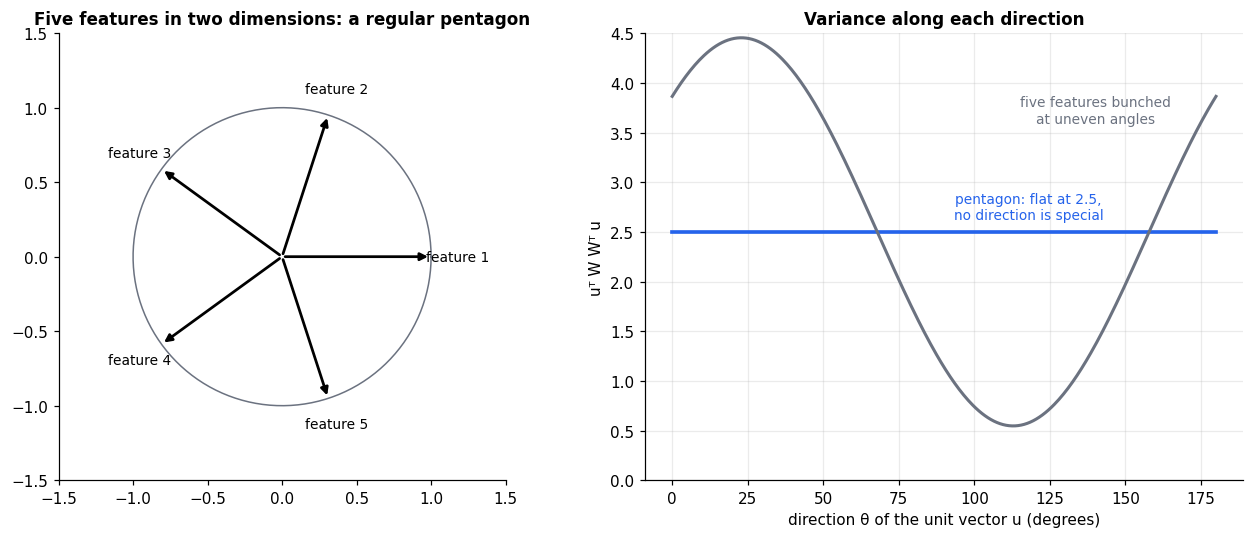

In [12]:
n = 5
phis = 2 * math.pi * torch.arange(n) / n
W = torch.stack([phis.cos(), phis.sin()])                  # (2, 5): five unit feature vectors, 72° apart

G_hidden = W @ W.T
print("W Wᵀ =\n", G_hidden, "\n(equals n/2 · I with n = 5)")
assert torch.allclose(G_hidden, (n / 2) * torch.eye(2))
print("\neigenvalues of WᵀW (5×5):", torch.linalg.eigvalsh(W.T @ W).flip(0))

for deg in (0, 17, 53):
    ph = math.radians(deg)
    R = torch.tensor([[math.cos(ph), -math.sin(ph)], [math.sin(ph), math.cos(ph)]])
    same = torch.allclose((R @ W) @ (R @ W).T, G_hidden)
    print(f"rotate the pentagon by {deg:>2}°: W Wᵀ unchanged -> {same}")
    assert same

# contrast: five unit features bunched together at uneven angles
angs_u = torch.deg2rad(torch.tensor([0.0, 8.0, 20.0, 35.0, 55.0]))
Wu = torch.stack([angs_u.cos(), angs_u.sin()])

thetas = torch.linspace(0, math.pi, 361)
U = torch.stack([thetas.cos(), thetas.sin()])
var_pent = (U * (G_hidden @ U)).sum(0)                     # uᵀ(WWᵀ)u
var_unev = (U * ((Wu @ Wu.T) @ U)).sum(0)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ax = axes[0]
ax.plot(circle[0], circle[1], color=C_IN, lw=1.0)
for k in range(n):
    ax.annotate("", xy=W[:, k].tolist(), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="black", lw=1.8), zorder=5)
    ax.annotate(f"feature {k + 1}", xy=(1.18 * W[0, k].item(), 1.18 * W[1, k].item()), ha="center", va="center", fontsize=9)
ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5); ax.set_aspect("equal"); ax.grid(False)
ax.set_title("Five features in two dimensions: a regular pentagon")

ax = axes[1]
ax.plot(torch.rad2deg(thetas), var_pent, color=C_OUT, lw=2.4)
ax.plot(torch.rad2deg(thetas), var_unev, color=C_IN, lw=2)
ax.text(118, 2.6, "pentagon: flat at 2.5,\nno direction is special", ha="center", va="bottom", fontsize=9, color=C_OUT)
ax.text(140, 3.6, "five features bunched\nat uneven angles", ha="center", fontsize=9, color=C_IN)
ax.set_ylim(0, 4.5); ax.set_xlabel("direction θ of the unit vector u (degrees)"); ax.set_ylabel("uᵀ W Wᵀ u")
ax.set_title("Variance along each direction")
plt.tight_layout(); plt.show()

## Try it yourself

1. **Bigger eigenspace.** Build a symmetric 4×4 matrix with eigenvalues $(7, 3, 3, 3)$ as $Q_0\Lambda Q_0^\top$. How many independent angles are needed to describe the freedom in choosing the three eigenvectors for $\lambda = 3$? Verify with a random rotation inside that eigenspace.
2. **Move the saturation point.** In Step 4, raise the perturbation size $\delta$ from 0.01 to 0.1. Where does the median error curve reach 45°, and does it track the line gap $= \delta$?
3. **More data.** In Step 5, increase $N$ from 300 to 3000 for the "gap 0.2" case. Predict from the $\sqrt{\lambda_i\lambda_j/N}$ rule how the spread of PC1 angles should change, then check.
4. **By hand.** For $\begin{pmatrix}2&1\\0&2\end{pmatrix}$, find the eigenvalue, the rank of $M - 2I$, and the single eigenvector. Is it defective?
5. **Other polygons.** Compute $WW^\top$ for six evenly spaced unit features in 2D, then for three at $0°, 120°, 240°$. What is it each time, and what about four features, $0°, 90°, 180°, 270°$?

## What to carry forward

- A repeated eigenvalue of a symmetric matrix has an **eigenspace** of dimension equal to its multiplicity. Every vector in it is an eigenvector, and any orthonormal basis of it is equally valid. The freedom is exactly an orthogonal matrix inside each eigenspace.
- What `eigh`, `svd` or any solver returns inside a degenerate eigenspace is arbitrary: a $10^{-10}$ nudge can rotate it by tens of degrees. The **projector onto the eigenspace** is stable, so ask questions about subspaces rather than individual vectors.
- **Near-degeneracy** is the practical version. An eigenvector's error is about noise / gap, so axes whose eigenvalues are closer than the noise are not identifiable. For PCA the noise is sampling error, about $\sqrt{\lambda_i\lambda_j/N}$.
- For non-symmetric matrices a repeated eigenvalue can be **defective**: fewer eigenvectors than eigenvalues, no eigenbasis, and eigenvalues that move like $\sqrt{\varepsilon}$ under perturbation.
- Symmetric structure produces exact degeneracy. A regular pentagon of features gives $WW^\top = \tfrac52 I$, so the variance is the same in every direction and no principal axis is privileged. In general, **when nothing privileges a basis, no method that only sees second-order statistics can recover one.** This is the opening for sparsity-based methods.

That completes the Phase 1 linear algebra notebooks. **Next, Phase 2:** the SVD, what it says about a matrix, and what it cannot tell us about sparse features.